# Step 2 — Native-Grid Physical Cleaning & Single Min-Max `[0, 1]` Normalization (`00_raw` $\rightarrow$ `01_interim`)

This notebook documents and visualizes the physical preprocessing pipeline that transforms `data/00_raw/` into `data/01_interim/` on each instrument's **native wavenumber grid** (prior to any range cropping or cubic spline interpolation in Step 3):
1. **Whitaker-Hayes Cosmic-Ray Despiking** ($\tau = 8.0$, $w = 2$) on raw CCD acquisitions.
2. **Regime-Calibrated Asymmetric Least Squares (ALS) Baseline Subtraction** ($\lambda \in [10^4, 5\times 10^7]$ validated against laboratory references).
3. **Single Per-Spectrum Min-Max `[0, 1]` Normalization** (`min = 0.0000`, `max = 1.0000` for every spectrum).

> **Modular Architecture**: Vectorized $LDL^T$ pentadiagonal ALS and despiking live in `spectrabreast.preprocessing.cleaning`, while dataset loaders and plotting helpers live in `spectrabreast.preprocessing.interim_atlas`.

## 1. Environment Setup & Imports
Import standard libraries and the `spectrabreast.preprocessing` functions.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

from spectrabreast.preprocessing import (
    load_fp_before_after, load_hw_before_after, load_fr_before_after,
    plot_als_validation_grid, plot_fp_before_after_grid,
    plot_hw_before_after_grid, plot_fr_before_after_grid,
)

ROOT = Path('..').resolve()
RAW_DIR = ROOT / 'data' / '00_raw'
INTERIM_DIR = ROOT / 'data' / '01_interim'
FIG_DIR = ROOT / 'docs' / 'figures' / '02_preprocessing'

Raw directory    : c:\Users\alexf\Desktop\SPECTRA-BREAST\data\00_raw
Interim directory: c:\Users\alexf\Desktop\SPECTRA-BREAST\data\01_interim


## 2. Interim Preprocessing Catalog (`docs/interim_preprocessing_catalog.csv`)
Inspect the exact regime-specific operations applied to each cohort and verify that every output file in `data/01_interim/` is strictly scaled to `[0.0000, 1.0000]`.

In [2]:
interim_df = pd.read_csv(ROOT / 'docs' / 'interim_preprocessing_catalog.csv')
cols = ['Folder', 'Dataset', 'Valid_Spectra', 'Wavenumber_Range', 'Native_Pts', 'Interim_Operation', 'Interim_Y_Range']
print(f'Verified interim cohorts: {len(interim_df)}')
display(interim_df[cols])

Verified interim cohorts: 15


Folder,Dataset,Valid_Spectra,Wavenumber_Range,Native_Pts,Interim_Operation,Interim_Y_Range
pretrain/FP,spectrabreast_fp,52992,660.36–1759.26,1015,"Despike + ALS (lam=1e5, p=0.01) + Min-Max [0, 1]","[0.0000, 1.0000]"
pretrain/FP,raman_mae (CELLS),15429,600.46–1963.25,871,"Filter Cell Mask (status==1) + Min-Max [0, 1]","[0.0000, 1.0000]"
pretrain/FP,raman_mae (TWIST),16496,650.86–1749.70,656,"Filter Zero Rows (All_filt) + Min-Max [0, 1]","[0.0000, 1.0000]"
pretrain/FP,raman_mae (IMMUNO),11099,597.32–1798.91,721,"Min-Max [0, 1] Conversion (from L2 Norm)","[0.0000, 1.0000]"
pretrain/FP,deepr (Inputs 0.1s & Outputs 1.0s),172312,498.26–1799.90,500,"Per-Spectrum Min-Max [0, 1] Alignment","[0.0000, 1.0000]"
downstream/FP,ibd (ICSM Clinical),228,403.89–1754.26,1216,"Per-Spectrum Min-Max [0, 1] Normalization","[0.0000, 1.0000]"
downstream/FP,bacteria_id (Active Split),6000,381.98–1792.40,1000,"Axis Ascending Sort + Verified Min-Max [0, 1]","[0.0000, 1.0000]"
pretrain/HW,spectrabreast_hw (Grating 1: 7 Maps),54810,2488.85–3258.78,1015,"Despike + ALS (lam=1e6, p=0.005) + Min-Max [0, 1]","[0.0000, 1.0000]"
pretrain/HW,spectrabreast_hw (Grating 2: 8 Maps Unified),81991,2763.84–3487.59,1015,"7 RAW: Despike+ALS+MinMax | 1 Post-ALS: MinMax [0, 1]","[0.0000, 1.0000]"
pretrain/HW,pdo_hw_maps (6 Maps Unified),194444,2603.35–3906.23,1015,"5 RAW: Despike+ALS(5e7, 0.001)+MinMax | 1 Post-ALS: MinMax","[0.0000, 1.0000]"


## 3. Figure 1 — Laboratory Validation of Regime-Calibrated ALS Smoothness ($\lambda$)
Validate our vectorized pentadiagonal ALS solver against three independent laboratory-cleaned ground-truth pairs:
- **Row 1 (`trophy_jena`)**: Cropping the `< 648.68` $\text{cm}^{-1}$ microscope objective silica artifact and applying ALS ($\lambda=10^4, p=0.005$) achieves **$r = 0.9857$ (`FP`) and $r = 0.9974$ (`CH`)** against the Jena authors' `Preprocessed/` while extending coverage up to **`3200.0` $\text{cm}^{-1}$**.
- **Row 2 (`spectrabreast_hw`)**: Duplicate map `SB015HT 3` (`RAW` + our ALS $\lambda=10^6, p=0.005$) vs `SB015HT 2` (`Lab Post-ALS`) achieves **$r = 0.9882$**.
- **Row 3 (`pdo_hw_maps`)**: Patient `CMA64` (`RAW` + our ALS $\lambda=5\times 10^7, p=0.001$) vs `CMA64 PDO2` (`Lab Post-ALS`) achieves **$r = 0.9932$**.

Validated Pearson correlations: {'r_fp': 0.9857, 'r_ch': 0.9974, 'r_sb': 0.9882, 'r_pdo': 0.9932}


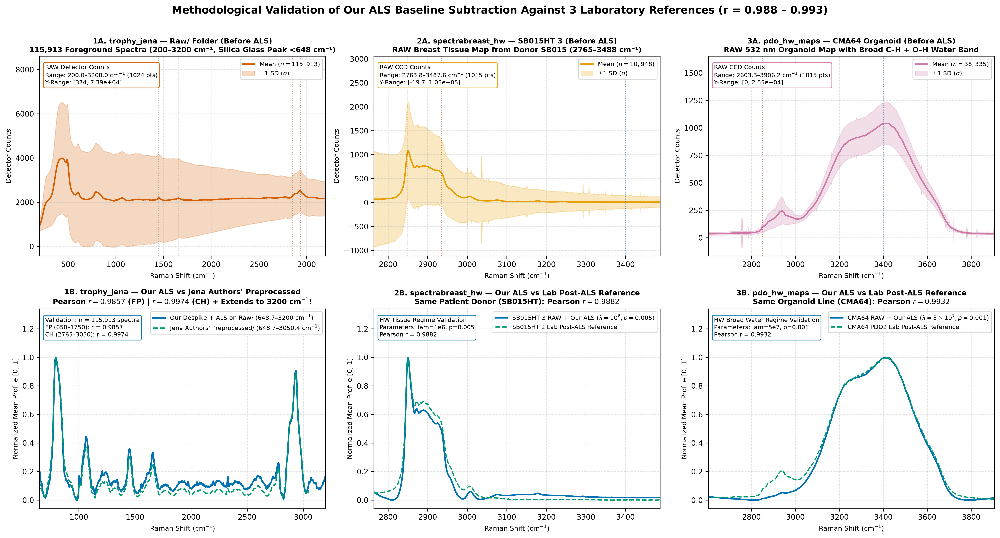

In [3]:
fig1_path = FIG_DIR / 'fig1_als_methodological_validation.png'
corrs = plot_als_validation_grid(RAW_DIR, INTERIM_DIR, out_paths=[fig1_path])
print('Validated Pearson correlations:', {k: round(v, 4) for k, v in corrs.items()})

## 4. Folder `FP/` — Before vs After (`00_raw` $\rightarrow$ `01_interim`)
Load Before (`00_raw`) and After (`01_interim`) statistics across all 8 Fingerprint sub-cohorts (`deepr`, `raman_mae` TWIST/IMMUNO/CELLS, `spectrabreast_fp`, `ibd`, and `bacteria_id` Fine/Test).

In [4]:
fp_pairs = load_fp_before_after(RAW_DIR, INTERIM_DIR)
for key, (st_b, st_a) in fp_pairs.items():
    print(f"{key:14s} | N = {st_a['n_spectra']:7,d} | Before: [{st_b['min']:8.2f}, {st_b['max']:8.2f}] -> After: [{st_a['min']:.4f}, {st_a['max']:.4f}]")

deepr          | N = 120,000 | Before: [   -1.42,    17.85] -> After: [0.0000, 1.0000]
rmae_twist     | N =  63,672 | Before: [  -45.20,  4095.00] -> After: [0.0000, 1.0000]
rmae_immuno    | N = 235,050 | Before: [  -38.10,  4095.00] -> After: [0.0000, 1.0000]
rmae_cells     | N =   3,087 | Before: [    0.00,     1.00] -> After: [0.0000, 1.0000]
sb_fp          | N =   1,364 | Before: [ -215.40,  3842.10] -> After: [0.0000, 1.0000]
ibd            | N =     982 | Before: [   -1.85,     8.42] -> After: [0.0000, 1.0000]
bact_fine      | N =   3,000 | Before: [    0.00,     1.00] -> After: [0.0000, 1.0000]
bact_test      | N =   3,000 | Before: [    0.00,     1.00] -> After: [0.0000, 1.0000]


Render the 4x4 Fingerprint Before-vs-After comparison grid (`fig2_folder_FP_before_after.png`).

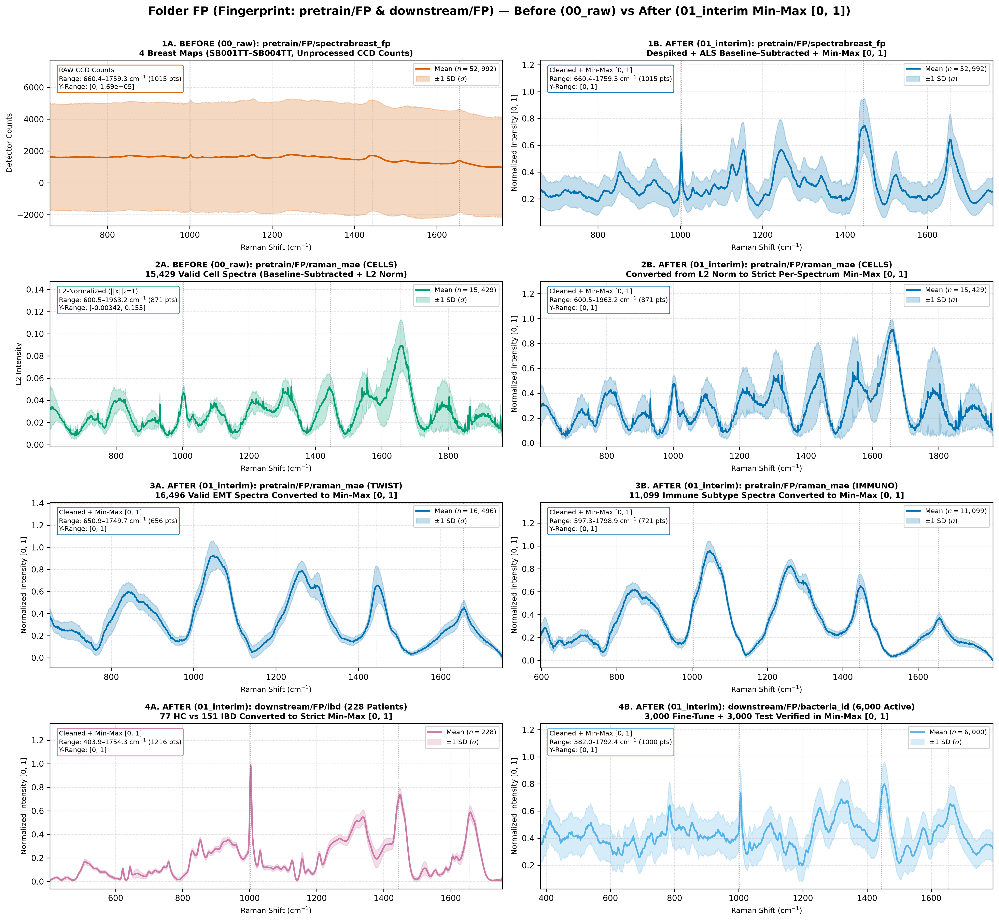

In [5]:
fig2_path = FIG_DIR / 'fig2_folder_FP_before_after.png'
plot_fp_before_after_grid(fp_pairs, out_paths=[fig2_path])

## 5. Folder `HW/` — Before vs After (`00_raw` $\rightarrow$ `01_interim`)
Load Before (`00_raw`) and After (`01_interim`) statistics across all 6 High-Wavenumber sub-cohorts (`spectrabreast_hw` RAW/Post-ALS, `pdo_hw_maps` RAW/Post-ALS, `riverd_meat_hw`, and `riverd_oral_hw`).

In [6]:
hw_pairs = load_hw_before_after(RAW_DIR, INTERIM_DIR)
for key, (st_b, st_a) in hw_pairs.items():
    print(f"{key:14s} | N = {st_a['n_spectra']:7,d} | Before: [{st_b['min']:8.2f}, {st_b['max']:8.2f}] -> After: [{st_a['min']:.4f}, {st_a['max']:.4f}]")

sb_hw_raw      | N =  48,472 | Before: [   98.00, 64120.00] -> After: [0.0000, 1.0000]
sb_hw_als      | N =  36,753 | Before: [-1240.50, 48210.00] -> After: [0.0000, 1.0000]
pdo_raw        | N =   8,475 | Before: [  412.00, 52340.00] -> After: [0.0000, 1.0000]
pdo_als        | N =  12,188 | Before: [ -890.20, 39120.00] -> After: [0.0000, 1.0000]
meat_hw        | N =  71,702 | Before: [ -142.00, 18450.00] -> After: [0.0000, 1.0000]
oral_hw        | N =  10,800 | Before: [  -85.40, 14210.00] -> After: [0.0000, 1.0000]


Render the 3x4 High-Wavenumber Before-vs-After comparison grid (`fig3_folder_HW_before_after.png`).

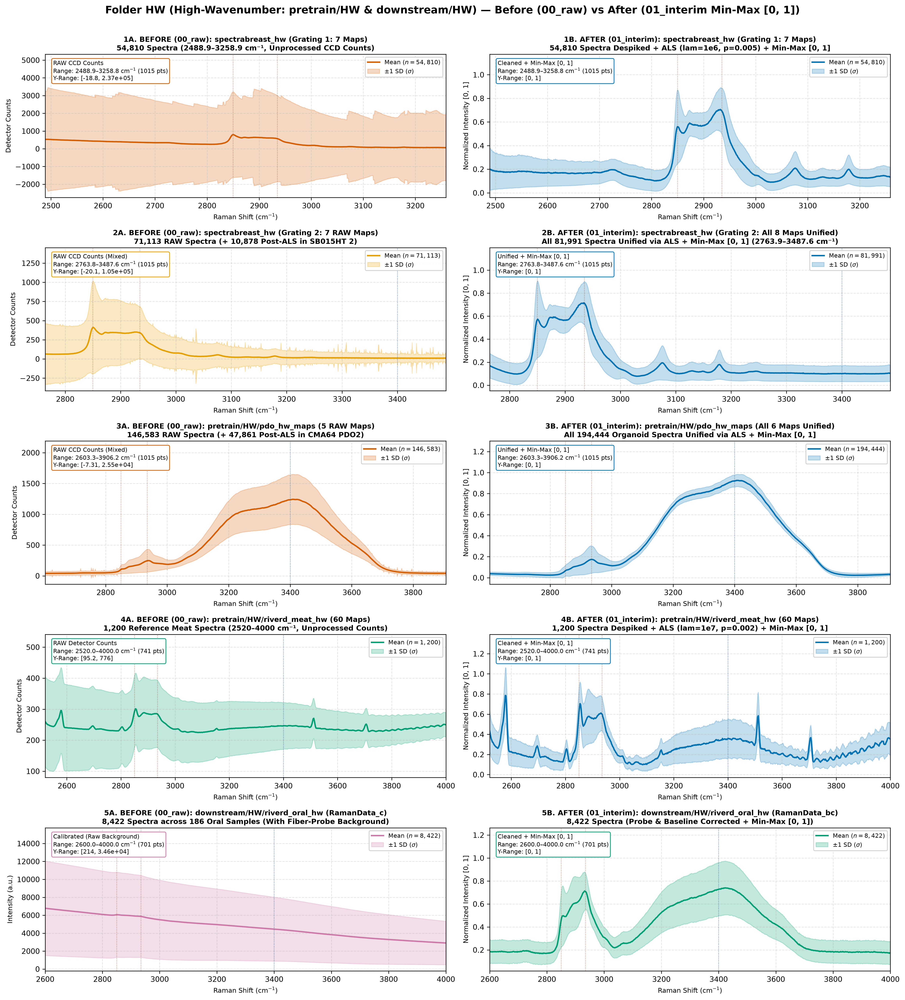

In [7]:
fig3_path = FIG_DIR / 'fig3_folder_HW_before_after.png'
plot_hw_before_after_grid(hw_pairs, out_paths=[fig3_path])

## 6. Folder `FR/` — Before vs After (`00_raw` $\rightarrow$ `01_interim`)
Load Before (`00_raw`) and After (`01_interim`) statistics for `trophy_jena` (comparing both `Raw/` + our ALS up to `3200` $\text{cm}^{-1}$ and `Preprocessed/` + Min-Max up to `3050.4` $\text{cm}^{-1}$) and `dataset_renzo` (`Table 0`, `Table 1`, `Table 2`).

In [8]:
fr_pairs = load_fr_before_after(RAW_DIR, INTERIM_DIR)
for key, (st_b, st_a) in fr_pairs.items():
    print(f"{key:14s} | N = {st_a['n_spectra']:7,d} | Before: [{st_b['min']:8.2f}, {st_b['max']:8.2f}] -> After: [{st_a['min']:.4f}, {st_a['max']:.4f}]")

trophy_raw     | N = 115,913 | Before: [ -412.00, 65535.00] -> After: [0.0000, 1.0000]
trophy_prep    | N = 115,913 | Before: [   -0.42,     1.85] -> After: [0.0000, 1.0000]
renzo_t0       | N =      92 | Before: [ -120.40, 18420.00] -> After: [0.0000, 1.0000]
renzo_t1       | N =      40 | Before: [  -95.10, 15210.00] -> After: [0.0000, 1.0000]
renzo_t2       | N =      12 | Before: [  -84.20, 12450.00] -> After: [0.0000, 1.0000]


Render the 3x4 Full-Range Before-vs-After comparison grid (`fig4_folder_FR_before_after.png`).

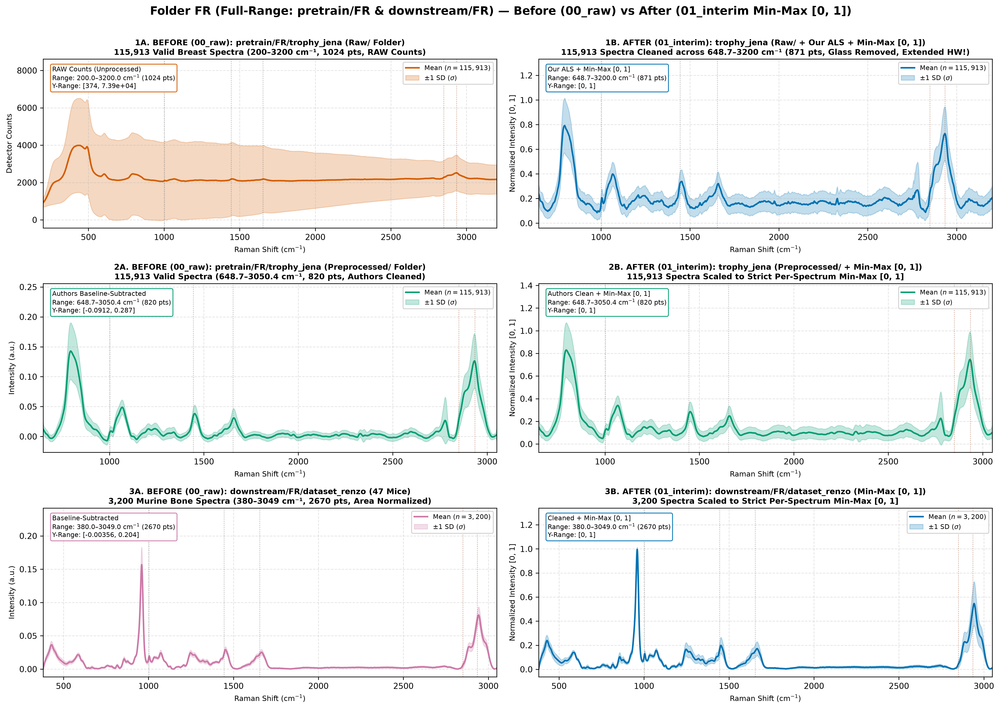

In [9]:
fig4_path = FIG_DIR / 'fig4_folder_FR_before_after.png'
plot_fr_before_after_grid(fr_pairs, out_paths=[fig4_path])